# 03 · Modeling
Logistic regression and XGBoost on the processed data; thresholds chosen by time-series CV (F2), test-set evaluation, and PR curve.
Requires `02_preprocessing.ipynb` to have been run. Saves `figures/pr_curve.png`.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv("../data/processed/train.csv", parse_dates=["timestamp"])
test = pd.read_csv("../data/processed/test.csv", parse_dates=["timestamp"])

X_train = train.drop(columns=["fail", "timestamp"]); y_train = train["fail"]
X_test = test.drop(columns=["fail", "timestamp"]);   y_test = test["fail"]
print(X_train.shape, X_test.shape)

(1096, 276) (471, 276)


In [3]:
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             confusion_matrix, precision_recall_curve)

def evaluate(name, y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    print(f"--- {name} (threshold {thr:.3f}) ---")
    print(f"PR AUC:  {average_precision_score(y_true, prob):.3f}  "
          f"(random = {y_true.mean():.3f})")
    print(f"ROC AUC: {roc_auc_score(y_true, prob):.3f}")
    print(f"Fails caught: {tp}/{tp+fn}  (recall {tp/(tp+fn):.1%})")
    print(f"False alarms: {fp}/{fp+tn} passing wafers flagged")

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", C=0.1, max_iter=5000))

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(
    n_estimators=300, max_depth=3, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.5,
    scale_pos_weight=pos_weight, eval_metric="aucpr", random_state=42)
print(f"scale_pos_weight = {pos_weight:.1f}")

scale_pos_weight = 13.1


In [5]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone

def oof_probs(model, X, y, n_splits=5):
    oof = np.full(len(y), np.nan)
    for tr, va in TimeSeriesSplit(n_splits).split(X):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        oof[va] = m.predict_proba(X.iloc[va])[:, 1]
    mask = ~np.isnan(oof)
    return y.values[mask], oof[mask]

def pick_threshold(y, p, beta=2):
    prec, rec, thr = precision_recall_curve(y, p)
    f = (1 + beta**2) * prec * rec / (beta**2 * prec + rec + 1e-12)
    return thr[np.argmax(f[:-1])]

thresholds = {}
for name, model in [("LogReg", logreg), ("XGBoost", xgb)]:
    y_oof, p_oof = oof_probs(model, X_train, y_train)
    thresholds[name] = pick_threshold(y_oof, p_oof)
    print(f"{name}: CV PR AUC {average_precision_score(y_oof, p_oof):.3f}, "
          f"threshold {thresholds[name]:.3f}")

LogReg: CV PR AUC 0.076, threshold 0.079


/Users/pranay/secom-yield-analysis/.secom/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pranay/secom-yield-analysis/.secom/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pranay/secom-yield-analysis/.secom/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pranay/secom-yield-analysis/.secom/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/pranay/secom-yield-analysis/.secom/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountere

XGBoost: CV PR AUC 0.117, threshold 0.017


In [6]:
logreg.fit(X_train, y_train)
xgb.fit(X_train, y_train)

p_lr = logreg.predict_proba(X_test)[:, 1]
p_xgb = xgb.predict_proba(X_test)[:, 1]

evaluate("LogReg", y_test, p_lr, thresholds["LogReg"])
evaluate("XGBoost", y_test, p_xgb, thresholds["XGBoost"])

/Users/pranay/secom-yield-analysis/.secom/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pranay/secom-yield-analysis/.secom/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pranay/secom-yield-analysis/.secom/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pranay/secom-yield-analysis/.secom/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/pranay/secom-yield-analysis/.secom/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountere

--- LogReg (threshold 0.079) ---
PR AUC:  0.077  (random = 0.055)
ROC AUC: 0.608
Fails caught: 4/26  (recall 15.4%)
False alarms: 61/445 passing wafers flagged
--- XGBoost (threshold 0.017) ---
PR AUC:  0.078  (random = 0.055)
ROC AUC: 0.630
Fails caught: 8/26  (recall 30.8%)
False alarms: 135/445 passing wafers flagged


/Users/pranay/secom-yield-analysis/.secom/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/pranay/secom-yield-analysis/.secom/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/pranay/secom-yield-analysis/.secom/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [7]:
scaler = logreg.named_steps["standardscaler"]
Z = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)
print("Max |scaled value| in test:", Z.abs().max().max())
print(Z.abs().max().sort_values(ascending=False).head(10))

Max |scaled value| in test: 12.133754384435193
s114    12.133754
s151    12.056953
s336    10.953089
s521    10.790601
s195    10.214692
s155     9.942409
s222     9.467061
s140     8.941910
s32      8.402027
s33      8.375466
dtype: float64


In [8]:
for s in ["s140", "s4", "s252", "s117"]:
    print(s, "| train unique:", X_train[s].nunique(),
          "| top train values:", X_train[s].value_counts().head(3).to_dict(),
          "| test min/max:", X_test[s].min(), X_test[s].max())

s140 | train unique: 364 | top train values: {0.3835: 10, 0.4695: 10, 0.1974: 10} | test min/max: 0.0522 3.225
s4 | train unique: 366 | top train values: {1.3101: 13, 1.5188: 10, 1.816: 10} | test min/max: 0.7647 3.8894
s252 | train unique: 1071 | top train values: {1.039875: 6, 5.6901675000000225: 6, 2.1781: 2} | test min/max: 1.039875 5.6901675000000225
s117 | train unique: 1069 | top train values: {60.643235: 6, 55.0210975: 6, 59.1158: 2} | test min/max: 55.0210975 60.643235


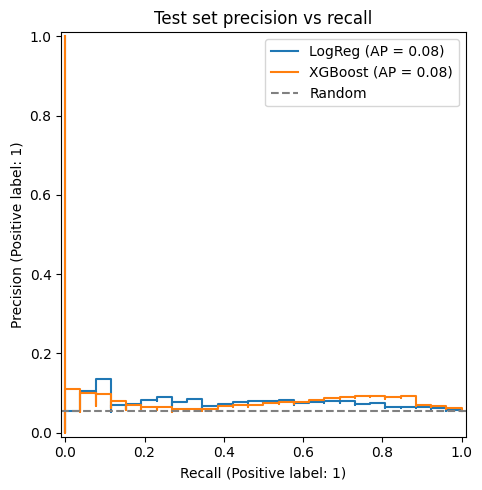

In [9]:
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y_test, p_lr, name="LogReg", ax=ax)
PrecisionRecallDisplay.from_predictions(y_test, p_xgb, name="XGBoost", ax=ax)
ax.axhline(y_test.mean(), color="gray", ls="--", label="Random")
ax.legend(); ax.set_title("Test set precision vs recall")
plt.tight_layout(); plt.savefig("../figures/pr_curve.png", dpi=150); plt.show()

In [10]:
import joblib
joblib.dump({"model": xgb, "threshold": thresholds["XGBoost"],
             "features": list(X_train.columns)}, "../data/processed/xgb.joblib")

['../data/processed/xgb.joblib']